# Multi-sensor glacial-lake tracking and GLOF hazard assessment — Hunza Valley

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SafeeAkmal/glof-hazard-assessment-hunza-valley/blob/master/notebooks/glof_pipeline.ipynb)

End-to-end pipeline for three sites in the Hunza basin (Shishper, Khurdopin, Passu/Borith Lake), built to run on Google Colab:

1. Pull every Sentinel-2 (optical) and Sentinel-1 (radar) acquisition, plus the Copernicus DEM, from Earth Engine for a set of time windows around the GLOF events.
2. Make automatic water labels from the optical water index (NDWI).
3. Train three small U-Nets: **optical only**, **radar only** (radar + DEM) and **fusion** (optical + radar + DEM).
4. Evaluate both on held-out years, including a simulated-cloud test.
5. Build a dense lake-area time series per lake (optical *and* radar-only dates).
6. Compute a simple hazard score and compare the lakes around each event (plus an exploratory per-lake version).

**Before running:** on Colab, set `Runtime → Change runtime type → T4 GPU`. The notebook also runs locally (Jupyter) if `earthengine authenticate` has been done once. The first download takes roughly 15–30 minutes; after that everything is cached (Google Drive on Colab, `data/raw/glof_minimal` locally).

## 1. Setup

In [5]:
%pip install -q segmentation-models-pytorch

In [6]:
import ee

PROJECT_ID = "numeric-amphora-495215-p6"  # @param {type:"string"} — replace with your own Earth Engine project

try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT_ID)
print("Earth Engine ready")

Earth Engine ready


In [7]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from scipy.ndimage import distance_transform_edt
from skimage.measure import label as cc_label
import torch
import torch.nn.functional as F
import segmentation_models_pytorch as smp

# On Colab, cache downloads in Google Drive so they survive runtime resets.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE_DIR = "/content/drive/MyDrive/glof_minimal"
except ImportError:                      # running locally
    CACHE_DIR = os.path.abspath(os.path.join("..", "data", "raw", "glof_minimal"))
os.makedirs(CACHE_DIR, exist_ok=True)
FIG_DIR = os.path.join(CACHE_DIR, "figures")      # every figure is also saved here
os.makedirs(FIG_DIR, exist_ok=True)


def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0); np.random.seed(0)
print("device:", DEVICE, "| cache:", CACHE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda | cache: /content/drive/MyDrive/glof_minimal


## 2. Configuration and sampling strategy

Satellites do not image every day: Sentinel-2 passes roughly every 5 days and Sentinel-1 every 6–12 days (12 after Sentinel-1B failed in Dec 2021). So instead of single dates, the notebook takes **every acquisition** inside these windows:

- **Dense event windows:** `DAYS_BEFORE` days before to `DAYS_AFTER` days after each GLOF (Khurdopin 21 Jul 2017, Shishper 29 May 2020 and 7 May 2022).
- **Anniversary windows:** ±`ANNIV_HALF` days around each event's calendar date (7 May, 29 May, 21 Jul) in every year of `YEARS`. This gives the same season in years without an event.

The **same windows are used for all three lakes**, so each lake gets a "same period, no event" comparison (Passu throughout, Khurdopin in 2020/2022, Shishper in 2017).

Lake points were located on Sentinel-2 imagery (the research-plan coordinates were 1–7 km off): Shishper's ice-dammed lake where the glacier blocks the side valley; Khurdopin's dammed lake at the glacier snout on the Shimshal River (2017); and for Passu, **Borith Lake** — the Passu glacier has no lake at its front in 2017–2022, and Borith Lake is the only lake next to it. The point is used to separate the lake from other water (e.g. the Hunza River) when measuring area; check it on the map in section 3.

In [8]:
LAKES = {
    "shishper":  dict(lat=36.358, lon=74.568, events={"Shishper breach 2020": "2020-05-29",
                                                    "Shishper GLOF 2022": "2022-05-07"}),
    "khurdopin": dict(lat=36.361, lon=75.449, events={"Khurdopin drainage 2017": "2017-07-21"}),
    "passu":     dict(lat=36.432, lon=74.862, events={}),   # Borith Lake, next to Passu glacier
}

DAYS_BEFORE, DAYS_AFTER = 90, 45   # dense window around each event
ANNIV_HALF = 15                    # +/- days around each event's calendar date, every year
YEARS = range(2017, 2023)
TEST_YEARS = {2019, 2021}          # labelled dates from these years are held out for testing

CRS = "EPSG:32643"     # UTM zone 43N, covers the Hunza basin
PIX = 10               # metres per pixel
SIZE = 448             # pixels per side -> 4.48 km box (divisible by 32 for the U-Net)
MIN_COVER = 0.95       # Sentinel-2 day must cover this fraction of the box
S1_PAIR_DAYS = 6       # max gap when pairing a Sentinel-1 scene with a Sentinel-2 day
CLOUD_PROB_THR = 60    # per-pixel cloud probability (%) treated as cloud
MIN_CLOUD_PX = 1000    # ignore cloud specks smaller than this (false positives on bright rock)
LAKE_RADIUS_M = 400    # water within this distance of the lake point counts as "the lake"
N_WORKERS = 8          # parallel Earth Engine downloads

ALL_EVENTS = {label: pd.Timestamp(day) for cfg in LAKES.values() for label, day in cfg["events"].items()}


def build_windows():
    day = pd.Timedelta(days=1)
    spans = [(e - DAYS_BEFORE * day, e + DAYS_AFTER * day) for e in ALL_EVENTS.values()]
    for month, dom in sorted({(e.month, e.day) for e in ALL_EVENTS.values()}):
        for y in YEARS:
            c = pd.Timestamp(year=y, month=month, day=dom)
            spans.append((c - ANNIV_HALF * day, c + ANNIV_HALF * day))
    spans.sort()
    merged = [list(spans[0])]
    for s, e in spans[1:]:
        if s <= merged[-1][1]:
            merged[-1][1] = max(merged[-1][1], e)
        else:
            merged.append([s, e])
    # end date is exclusive for Earth Engine's filterDate
    return [(s.strftime("%Y-%m-%d"), (e + day).strftime("%Y-%m-%d")) for s, e in merged]


WINDOWS = build_windows()
for s, e in WINDOWS:
    print(f"{s} -> {e}  ({(pd.Timestamp(e) - pd.Timestamp(s)).days} days)")
print("total days covered:", sum((pd.Timestamp(e) - pd.Timestamp(s)).days for s, e in WINDOWS))

2017-04-22 -> 2017-09-05  (136 days)
2018-04-22 -> 2018-06-14  (53 days)
2018-07-06 -> 2018-08-06  (31 days)
2019-04-22 -> 2019-06-14  (53 days)
2019-07-06 -> 2019-08-06  (31 days)
2020-02-29 -> 2020-08-06  (159 days)
2021-04-22 -> 2021-06-14  (53 days)
2021-07-06 -> 2021-08-06  (31 days)
2022-02-06 -> 2022-06-22  (136 days)
2022-07-06 -> 2022-08-06  (31 days)
total days covered: 714


## 3. Area of interest and visual check

In [9]:
def lake_grid(cfg):
    # Snap a SIZE x SIZE pixel box, centred on the lake point, to the 10 m UTM grid.
    x, y = ee.Geometry.Point([cfg["lon"], cfg["lat"]]).transform(CRS, 1).coordinates().getInfo()
    half = SIZE * PIX / 2
    x0 = round((x - half) / PIX) * PIX
    y1 = round((y + half) / PIX) * PIX
    grid = {"dimensions": {"width": SIZE, "height": SIZE},
            "affineTransform": {"scaleX": PIX, "shearX": 0, "translateX": x0,
                                "shearY": 0, "scaleY": -PIX, "translateY": y1},
            "crsCode": CRS}
    geom = ee.Geometry.Rectangle([x0, y1 - SIZE * PIX, x0 + SIZE * PIX, y1], CRS, False)
    lake_rc = (int((y1 - y) / PIX), int((x - x0) / PIX))   # lake point in pixel (row, col)
    return grid, geom, lake_rc

for name, cfg in LAKES.items():
    cfg["grid"], cfg["geom"], cfg["lake_rc"] = lake_grid(cfg)
    print(name, "lake pixel (row, col):", cfg["lake_rc"])

shishper lake pixel (row, col): (223, 224)
khurdopin lake pixel (row, col): (223, 224)
passu lake pixel (row, col): (223, 224)


In [10]:
import folium

def ee_layer(m, image, vis, name):
    url = image.getMapId(vis)["tile_fetcher"].url_format
    folium.TileLayer(tiles=url, attr="Google Earth Engine", name=name, overlay=True).add_to(m)

m = folium.Map(location=[36.38, 75.0], zoom_start=10)
summer = (ee.ImageCollection("COPERNICUS/S2_HARMONIZED")
          .filterDate("2021-07-01", "2021-09-30")
          .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
          .median())
ee_layer(m, summer, {"bands": ["B4", "B3", "B2"], "min": 0, "max": 3000}, "S2 summer 2021")
for name, cfg in LAKES.items():
    box = cfg["geom"].transform("EPSG:4326", 1).coordinates().getInfo()[0]
    folium.Polygon([(lat, lon) for lon, lat in box], color="yellow", fill=False, tooltip=name).add_to(m)
    folium.Marker([cfg["lat"], cfg["lon"]], tooltip=name).add_to(m)
m.add_child(folium.LatLngPopup())   # click the map to read a lat/lon
folium.LayerControl().add_to(m)
m

If a marker is not on its lake, click the lake on the map, copy the lat/lon into `LAKES` (section 2), and re-run sections 2–3. If you change a lake's position after downloading, delete that lake's folder in `CACHE_DIR` first.

## 4. Download from Earth Engine

For each lake and window the notebook lists every Sentinel-2 day (that covers the box) and every Sentinel-1 day (one orbit direction per lake), then saves one file per date:

- **Sentinel-2 days:** `B2 B3 B4 B8` (reflectance 0–1) + cloud probability, paired with the nearest Sentinel-1 scene within `S1_PAIR_DAYS`.
- **Radar-only days** (Sentinel-1 with no Sentinel-2 that day): `VV VH` only; optical is marked as missing.
- **Static per lake:** DEM elevation and slope.

Downloads run in parallel and skip files that already exist, so the cell can be re-run to resume after an interruption.

In [11]:
S2 = ee.ImageCollection("COPERNICUS/S2_HARMONIZED")
S2_CLOUD = ee.ImageCollection("COPERNICUS/S2_CLOUD_PROBABILITY")
S1 = (ee.ImageCollection("COPERNICUS/S1_GRD")
      .filter(ee.Filter.eq("instrumentMode", "IW"))
      .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
      .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH")))
DEM = (ee.ImageCollection("COPERNICUS/DEM/GLO30").select("DEM").mosaic()
       .setDefaultProjection("EPSG:4326", None, 30))
NODATA = -9999


def fetch(image, grid):
    # Download an ee.Image on the lake grid as a (bands, H, W) float32 array.
    arr = ee.data.computePixels({"expression": image.unmask(NODATA).toFloat(),
                                 "fileFormat": "NUMPY_NDARRAY", "grid": grid})
    out = np.stack([arr[b] for b in arr.dtype.names]).astype("float32")
    out[out == NODATA] = np.nan
    return out


def day_mosaic(col, geom, day):
    d = ee.Date(day)
    return col.filterBounds(geom).filterDate(d, d.advance(1, "day")).mosaic()


def day_cloud(geom, day):
    # Cloud probability for that day; 0 (assume clear) if the cloud product is missing.
    d = ee.Date(day)
    col = S2_CLOUD.filterBounds(geom).filterDate(d, d.advance(1, "day"))
    return ee.Image(ee.Algorithms.If(col.size().gt(0), col.mosaic().select("probability"),
                                     ee.Image.constant(0).rename("probability")))


def distinct_days(col):
    return col.aggregate_array("system:time_start").map(lambda ms: ee.Date(ms).format("YYYY-MM-dd")).distinct()


def s2_days(geom, start, end):
    # Every Sentinel-2 day in [start, end) with its box coverage and cloud fraction.
    days = distinct_days(S2.filterBounds(geom).filterDate(start, end))

    def stats(day):
        cover = day_mosaic(S2, geom, day).select("B2").gt(0).unmask(0) \
            .reduceRegion(ee.Reducer.mean(), geom, 60).get("B2")
        cloud = day_cloud(geom, day).gt(CLOUD_PROB_THR) \
            .reduceRegion(ee.Reducer.mean(), geom, 60).get("probability")
        return ee.Feature(None, {"day": day, "cover": cover, "cloud": cloud})

    rows = [f["properties"] for f in ee.FeatureCollection(days.map(stats)).getInfo()["features"]]
    return [dict(day=r["day"], cloud=r.get("cloud") or 0.0) for r in rows if (r.get("cover") or 0) >= MIN_COVER]


def lake_orbit(geom):
    # Use one Sentinel-1 orbit direction per lake (whichever has more scenes).
    col = S1.filterBounds(geom).filterDate("2017-01-01", "2023-01-01")
    n_asc = col.filter(ee.Filter.eq("orbitProperties_pass", "ASCENDING")).size().getInfo()
    n_desc = col.filter(ee.Filter.eq("orbitProperties_pass", "DESCENDING")).size().getInfo()
    return "ASCENDING" if n_asc >= n_desc else "DESCENDING"


def plan_lake(name, cfg):
    # List every date to download for one lake (cached as plan.json).
    folder = os.path.join(CACHE_DIR, name)
    os.makedirs(folder, exist_ok=True)
    path = os.path.join(folder, "plan.json")
    if os.path.exists(path):
        return json.load(open(path))
    geom = cfg["geom"]
    orbit = lake_orbit(geom)
    s1_col = S1.filterBounds(geom).filter(ee.Filter.eq("orbitProperties_pass", orbit))
    plan = []
    for start, end in WINDOWS:
        opt = s2_days(geom, start, end)
        radar = sorted(distinct_days(s1_col.filterDate(start, end)).getInfo())
        radar_ts = [pd.Timestamp(d) for d in radar]
        for o in opt:
            t = pd.Timestamp(o["day"])
            gaps = [abs((r - t).days) for r in radar_ts]
            pair = radar[int(np.argmin(gaps))] if gaps and min(gaps) <= S1_PAIR_DAYS else None
            plan.append(dict(date=o["day"], s2=True, cloud_frac=round(o["cloud"], 3), s1_date=pair))
        opt_days = {o["day"] for o in opt}
        plan += [dict(date=r, s2=False, cloud_frac=1.0, s1_date=r) for r in radar if r not in opt_days]
        print(f"  {name} {start}..{end}: {len(opt)} optical days, {len(radar)} radar days")
    plan.sort(key=lambda p: p["date"])
    json.dump(dict(orbit=orbit, scenes=plan), open(path, "w"))
    return dict(orbit=orbit, scenes=plan)


def download_scene(name, cfg, orbit, scene):
    path = os.path.join(CACHE_DIR, name, scene["date"] + ".npz")
    if os.path.exists(path):
        return
    grid, geom = cfg["grid"], cfg["geom"]
    if scene["s2"]:
        opt = day_mosaic(S2, geom, scene["date"]).select(["B2", "B3", "B4", "B8"]).divide(10000)
        a = fetch(opt.addBands(day_cloud(geom, scene["date"])), grid)
        s2, cloud = a[:4], np.nan_to_num(a[4], nan=100)
    else:
        s2, cloud = np.full((4, SIZE, SIZE), np.nan, "float32"), np.full((SIZE, SIZE), 100, "float32")
    if scene["s1_date"]:
        s1_img = day_mosaic(S1.filter(ee.Filter.eq("orbitProperties_pass", orbit)), geom, scene["s1_date"])
        s1 = fetch(s1_img.select(["VV", "VH"]), grid)
    else:
        s1 = np.full((2, SIZE, SIZE), np.nan, "float32")
    np.savez_compressed(path, s2=s2.astype("float16"), s1=s1.astype("float16"),
                        cloud=np.clip(cloud, 0, 100).astype("uint8"))


for name, cfg in LAKES.items():
    print(name)
    plan = plan_lake(name, cfg)
    static_path = os.path.join(CACHE_DIR, name, "static.npz")
    if not os.path.exists(static_path):
        st = fetch(DEM.rename("dem").addBands(ee.Terrain.slope(DEM).rename("slope")).resample("bilinear"), cfg["grid"])
        np.savez_compressed(static_path, dem=st[0], slope=st[1])
    todo = [s for s in plan["scenes"] if not os.path.exists(os.path.join(CACHE_DIR, name, s["date"] + ".npz"))]
    n_opt = sum(s["s2"] for s in plan["scenes"])
    print(f"  {len(plan['scenes'])} dates ({n_opt} optical, {len(plan['scenes']) - n_opt} radar-only), "
          f"orbit {plan['orbit']}, {len(todo)} to download")
    with ThreadPoolExecutor(N_WORKERS) as pool:
        for i, _ in enumerate(pool.map(lambda s: download_scene(name, cfg, plan["orbit"], s), todo), 1):
            if i % 25 == 0 or i == len(todo):
                print(f"    {i}/{len(todo)}")

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for COPERNICUS/DEM/GLO30! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by COPERNICUS/DEM/GLO30_2024_1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_DEM_GLO30

  warnings.warn(warning, category=DeprecationWarning)


shishper
  215 dates (121 optical, 94 radar-only), orbit ASCENDING, 0 to download
khurdopin
  313 dates (248 optical, 65 radar-only), orbit DESCENDING, 0 to download
passu
  202 dates (121 optical, 81 radar-only), orbit DESCENDING, 0 to download


In [12]:
DATA = {}
for name in LAKES:
    folder = os.path.join(CACHE_DIR, name)
    plan = json.load(open(os.path.join(folder, "plan.json")))
    meta = pd.DataFrame(plan["scenes"])
    files = [np.load(os.path.join(folder, d + ".npz")) for d in meta.date]
    st = np.load(os.path.join(folder, "static.npz"))
    DATA[name] = dict(s2=np.stack([f["s2"] for f in files]), s1=np.stack([f["s1"] for f in files]),
                      cloud=np.stack([f["cloud"] for f in files]), dem=st["dem"], slope=st["slope"], meta=meta)
    DATA[name]["meta"]["date"] = pd.to_datetime(meta.date)
    print(f"{name}: {len(meta)} dates ({meta.s2.sum()} optical, {(~meta.s2).sum()} radar-only, "
          f"{meta.s1_date.notna().sum()} with radar)")

shishper: 215 dates (121 optical, 94 radar-only, 215 with radar)
khurdopin: 313 dates (248 optical, 65 radar-only, 301 with radar)
passu: 202 dates (121 optical, 81 radar-only, 197 with radar)


## 5. Automatic water labels

Water = NDWI > `NDWI_THR`, low NIR (rules out snow, ice and cloud), green above a minimum (rules out deep shadow), and gentle slope (rules out steep shadowed cliffs).

Only near-clear images are labelled (cloud ≤ `MAX_CLOUD_FRAC` of the box, not mostly snow/haze); pixels within `CLOUD_BUFFER_PX` of cloud get label `255` and are ignored. Cloudy and radar-only dates get no label but are still used for the time series. These rules were tuned by inspecting overlays; they are a shortcut instead of hand-drawn masks. Frozen or snow-covered lakes (common in Feb–Apr) are labelled as land.

In [13]:
IGNORE = 255


def remove_small(mask, min_px):
    comp = cc_label(mask)
    sizes = np.bincount(comp.ravel())
    return mask & (sizes[comp] >= min_px)


def ndwi(s2):
    g, n = s2[..., 1, :, :], s2[..., 3, :, :]
    return (g - n) / (g + n + 1e-6)


NDWI_THR = 0.2          # water threshold
MAX_CLOUD_FRAC = 0.1    # only label images with at most this much cloud in the box
CLOUD_BUFFER_PX = 15    # ignore pixels within 150 m of cloud
MAX_BRIGHT_FRAC = 0.4   # skip images that are mostly snow / haze


def cloud_mask(cloud):
    return remove_small(cloud >= CLOUD_PROB_THR, MIN_CLOUD_PX)


def make_label(s2, cloud, slope):
    s2 = s2.astype("float32")
    w = ndwi(s2)
    no_label = np.full(w.shape, IGNORE, np.uint8)
    cloudy = cloud_mask(cloud) | ~np.isfinite(w)
    if cloudy.mean() > MAX_CLOUD_FRAC or (np.nan_to_num(s2[0]) > 0.35).mean() > MAX_BRIGHT_FRAC:
        return no_label                             # too cloudy, snowy or radar-only
    clear = ~(distance_transform_edt(~cloudy) < CLOUD_BUFFER_PX) if cloudy.any() else ~cloudy
    if clear.mean() < 0.3:
        return no_label
    water = (w > NDWI_THR) & (s2[3] < 0.12) & (s2[1] > 0.03) & (slope < 20) & clear
    water = remove_small(water, 50)
    lab = water.astype(np.uint8)
    lab[~clear] = IGNORE
    return lab


for name, d in DATA.items():
    d["label"] = np.stack([make_label(d["s2"][t], d["cloud"][t], d["slope"]) for t in range(len(d["meta"]))])
    d["meta"]["labelled"] = (d["label"] != IGNORE).mean(axis=(1, 2)) > 0.3
    print(f"{name}: {d['meta'].labelled.sum()} labelled dates")

shishper: 40 labelled dates
khurdopin: 99 labelled dates
passu: 52 labelled dates


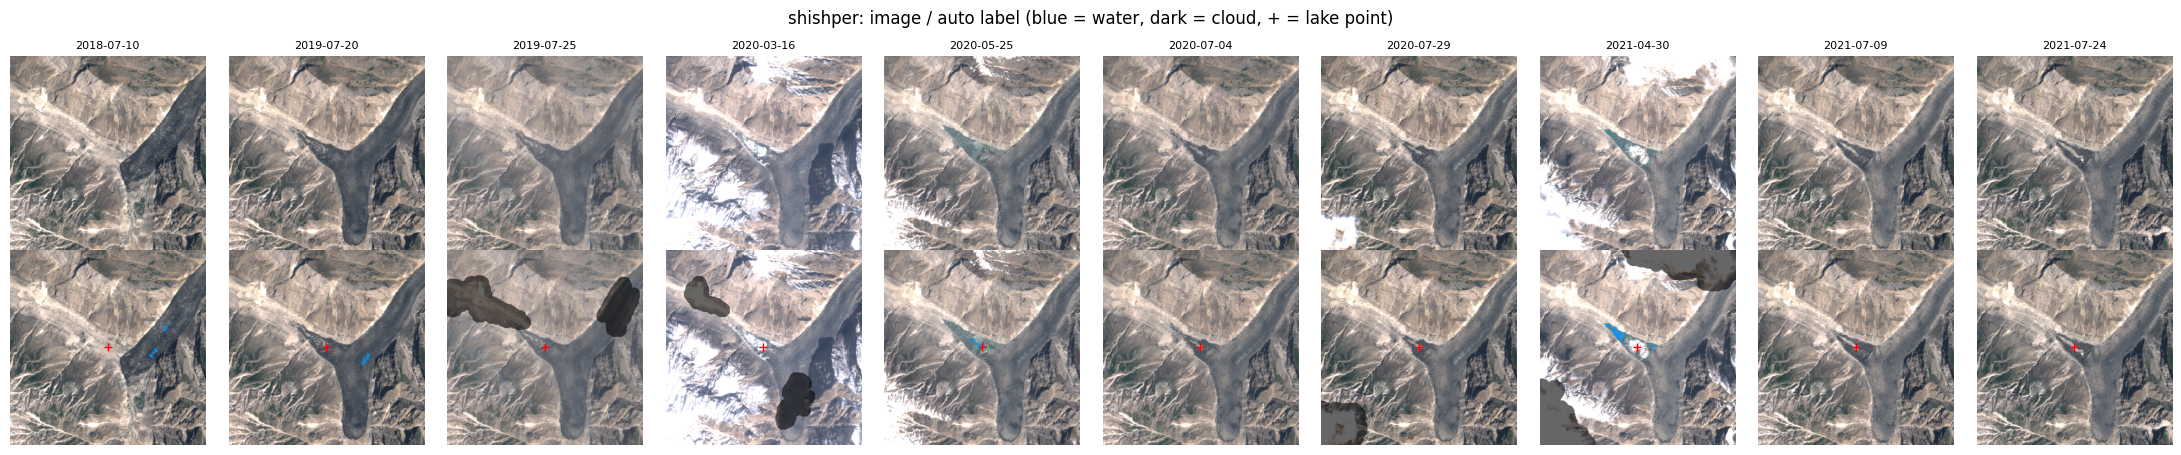

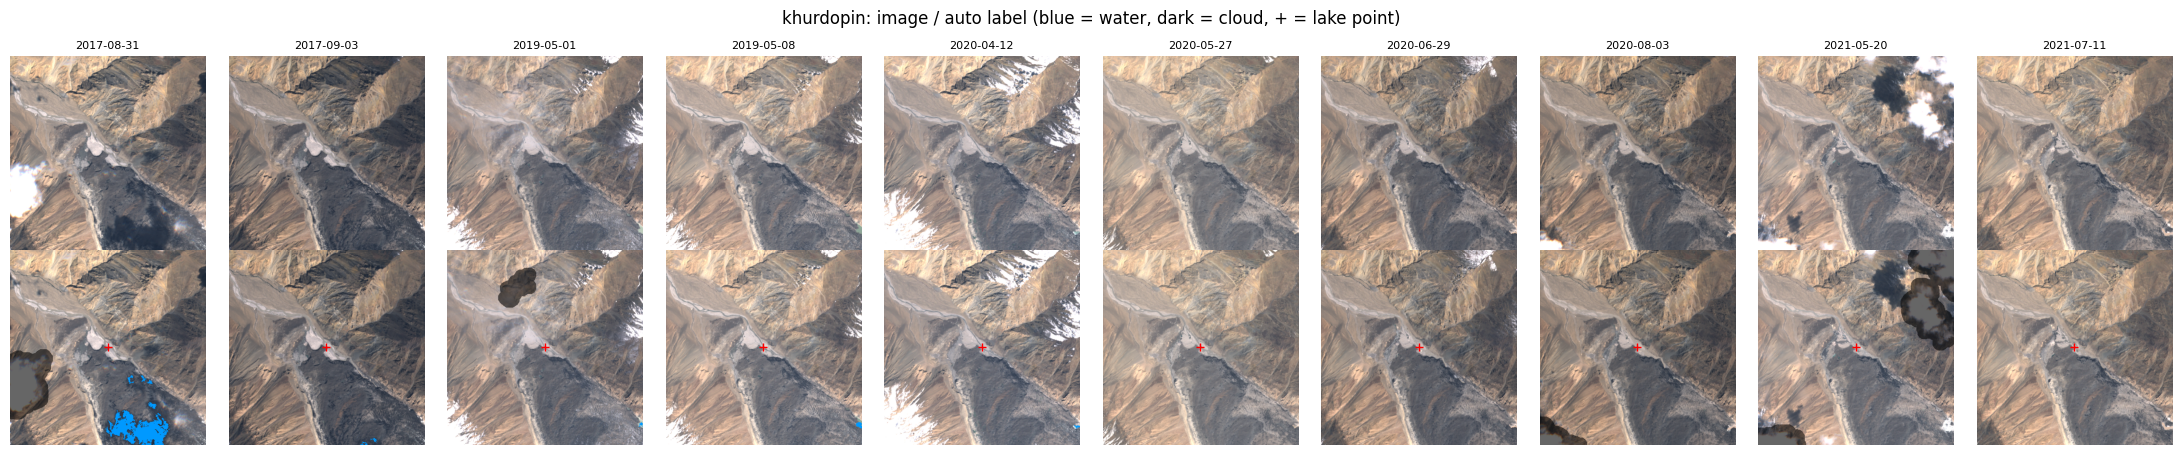

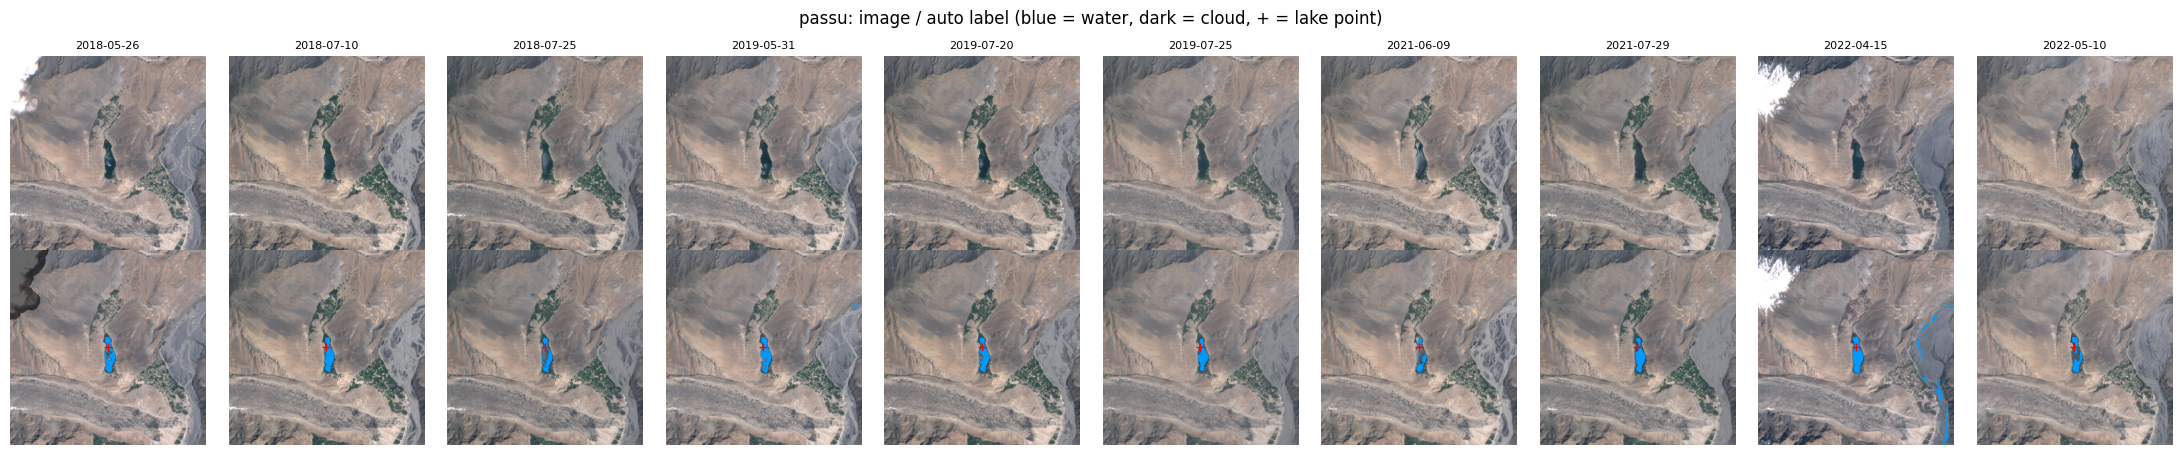

In [14]:
def rgb(s2):
    return np.clip(np.nan_to_num(s2[[2, 1, 0]].astype("float32").transpose(1, 2, 0)) / 0.3, 0, 1)


N_SHOW = 10   # random labelled dates per lake to inspect
for name, d in DATA.items():
    idx = np.where(d["meta"].labelled)[0]
    idx = np.sort(np.random.choice(idx, min(N_SHOW, len(idx)), replace=False))
    fig, axes = plt.subplots(2, len(idx), figsize=(2.2 * len(idx), 4.6), squeeze=False)
    for j, t in enumerate(idx):
        axes[0, j].imshow(rgb(d["s2"][t])); axes[0, j].set_title(d["meta"].date[t].date(), fontsize=8)
        ov = rgb(d["s2"][t]).copy()
        ov[d["label"][t] == 1] = [0, 0.6, 1]
        ov[d["label"][t] == IGNORE] *= 0.4
        axes[1, j].imshow(ov)
        r, c = LAKES[name]["lake_rc"]; axes[1, j].plot(c, r, "r+")
    for a in axes.ravel(): a.axis("off")
    fig.suptitle(f"{name}: image / auto label (blue = water, dark = cloud, + = lake point)")
    plt.tight_layout(); savefig(f"labels_{name}.png"); plt.show()

## 6. Model inputs and train/test split

- **Optical only:** B2, B3, B4, B8, NDWI (5 channels)
- **Radar only:** VV, VH, elevation, slope (4 channels) — ablation: what can radar + terrain do alone?
- **Fusion:** all of the above (9 channels)

Channels are standardised with the mean/std of training images. Optical channels are set to 0 (= the mean) wherever the pixel is cloudy or optical data is missing, so the model learns not to trust them there.

**Split by year:** labelled dates from `TEST_YEARS` are the test set; all other labelled dates train. Neighbouring dates look almost identical, so a random split would leak.

In [15]:
N_OPT = 5
OPTICAL = list(range(N_OPT))      # B2, B3, B4, B8, NDWI
RADAR = list(range(N_OPT, 9))     # VV, VH, elevation, slope
FUSION = list(range(9))


def build_inputs(d, t):
    s2 = d["s2"][t].astype("float32")
    opt = np.concatenate([s2, ndwi(s2)[None]], 0)                                    # 5 optical
    other = np.concatenate([d["s1"][t].astype("float32"), d["dem"][None], d["slope"][None]], 0)  # 4 radar/terrain
    return np.concatenate([opt, other], 0)


train_idx, test_idx = [], []
for name, d in DATA.items():
    for t in np.where(d["meta"].labelled)[0]:
        (test_idx if d["meta"].date[t].year in TEST_YEARS else train_idx).append((name, t))
print("train images:", len(train_idx), "| test images:", len(test_idx))

sample = [train_idx[i] for i in np.random.choice(len(train_idx), min(60, len(train_idx)), replace=False)]
stack = np.stack([build_inputs(DATA[n], t) for n, t in sample])
MEAN = np.nanmean(stack, axis=(0, 2, 3))
STD = np.nanstd(stack, axis=(0, 2, 3)) + 1e-6
del stack


def normalise(x, cloud):
    x = (x - MEAN[:, None, None]) / STD[:, None, None]
    x[:N_OPT, cloud_mask(cloud)] = 0
    return np.nan_to_num(x, nan=0.0).astype("float16")


for d in DATA.values():
    d["xn"] = np.stack([normalise(build_inputs(d, t), d["cloud"][t]) for t in range(len(d["meta"]))])
    del d["s1"]   # no longer needed; frees memory

train images: 137 | test images: 54


## 7. Train the three U-Nets (3 seeds each)

Identical architecture and settings; only the input channels differ. The fusion model is also trained with optical-channel dropout.

- **Balanced crop sampling.** Lake water covers well under 1% of the pixels, so most random crops contain no water and a model can reach a low loss by predicting "no water" everywhere. Half of the training crops are therefore centred on a random water pixel; the other half are random.
- **Seeds.** Each model is trained with `SEEDS = [0, 1, 2]`. Every seed has its own random-number generator, so the batches a model sees do not depend on which models were trained before it. Results are reported as mean ± sd across seeds.

Training time, model size and peak GPU memory are recorded for the computational-cost table.

In [16]:
import time

CROP, BATCH = 128, 16
STEPS = 3000 if DEVICE == "cuda" else 1500   # fewer steps when training on CPU
SEEDS = [0, 1, 2]
POS_FRAC = 0.5                                # share of training crops centred on lake water

WATER_PX = {(n, t): np.argwhere(DATA[n]["label"][t] == 1) for n, t in train_idx}
POS_IDX = [k for k, v in WATER_PX.items() if len(v)]
print(f"{len(POS_IDX)} of {len(train_idx)} training images contain water")


def sample_batch(channels, optical_dropout, rng):
    xs, ys = [], []
    for _ in range(BATCH):
        if POS_IDX and rng.random() < POS_FRAC:          # crop around a random water pixel
            n, t = POS_IDX[rng.integers(len(POS_IDX))]
            pr, pc = WATER_PX[(n, t)][rng.integers(len(WATER_PX[(n, t)]))]
            r = int(np.clip(pr - rng.integers(CROP), 0, SIZE - CROP))
            c = int(np.clip(pc - rng.integers(CROP), 0, SIZE - CROP))
        else:                                            # random crop
            n, t = train_idx[rng.integers(len(train_idx))]
            r, c = rng.integers(0, SIZE - CROP, 2)
        x = DATA[n]["xn"][t][channels, r:r + CROP, c:c + CROP].astype("float32")
        y = DATA[n]["label"][t][r:r + CROP, c:c + CROP]
        if rng.random() < 0.5: x, y = x[:, :, ::-1], y[:, ::-1]
        if rng.random() < 0.5: x, y = x[:, ::-1], y[::-1]
        if optical_dropout and rng.random() < 0.3:
            x[:N_OPT] = 0                                # pretend the whole crop is cloudy
        xs.append(x.copy()); ys.append(y.copy())
    return torch.from_numpy(np.stack(xs)).to(DEVICE), torch.from_numpy(np.stack(ys)).to(DEVICE)


def masked_loss(logits, y):
    valid = (y != IGNORE).float()
    target = (y == 1).float()
    bce = F.binary_cross_entropy_with_logits(logits, target, weight=valid)
    p = torch.sigmoid(logits) * valid
    dice = 1 - (2 * (p * target).sum() + 1) / (p.sum() + (target * valid).sum() + 1)
    return bce + dice


def train(channels, optical_dropout=False, seed=0):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = smp.Unet("resnet18", encoder_weights="imagenet", in_channels=len(channels), classes=1).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, STEPS)
    model.train()
    for step in range(STEPS):
        x, y = sample_batch(channels, optical_dropout, rng)
        loss = masked_loss(model(x)[:, 0], y)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if step % 1000 == 0 or step == STEPS - 1:
            print(f"    step {step:4d}  loss {loss.item():.3f}")
    return model.eval()


MODELS = {"optical": (OPTICAL, False), "radar": (RADAR, False), "fusion": (FUSION, True)}
models, compute = {}, []
for name, (channels, dropout) in MODELS.items():
    for seed in SEEDS:
        print(f"{name} model ({len(channels)} channels), seed {seed}")
        if DEVICE == "cuda":
            torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        t0 = time.time()
        models[(name, seed)] = train(channels, optical_dropout=dropout, seed=seed)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        compute.append(dict(model=name, seed=seed, channels=len(channels),
                            parameters=sum(p.numel() for p in models[(name, seed)].parameters()),
                            train_minutes=round((time.time() - t0) / 60, 2),
                            peak_gpu_memory_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if DEVICE == "cuda" else None))
torch.save({f"{m}_seed{sd}": net.state_dict() for (m, sd), net in models.items()}, os.path.join(CACHE_DIR, "models.pt"))
print("trained on:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")

74 of 137 training images contain water
optical model (5 channels), seed 0


    step    0  loss 1.786
    step 1000  loss 0.170
    step 2000  loss 0.172
    step 2999  loss 0.132
optical model (5 channels), seed 1
    step    0  loss 1.714
    step 1000  loss 0.427
    step 2000  loss 0.125
    step 2999  loss 0.086
optical model (5 channels), seed 2
    step    0  loss 1.598
    step 1000  loss 0.304
    step 2000  loss 0.338
    step 2999  loss 0.099
radar model (4 channels), seed 0
    step    0  loss 1.787
    step 1000  loss 0.407
    step 2000  loss 0.242
    step 2999  loss 0.366
radar model (4 channels), seed 1
    step    0  loss 1.710
    step 1000  loss 0.447
    step 2000  loss 0.240
    step 2999  loss 0.173
radar model (4 channels), seed 2
    step    0  loss 1.606
    step 1000  loss 0.577
    step 2000  loss 0.195
    step 2999  loss 0.243
fusion model (9 channels), seed 0
    step    0  loss 1.783
    step 1000  loss 0.228
    step 2000  loss 0.200
    step 2999  loss 0.175
fusion model (9 channels), seed 1
    step    0  loss 1.736
    step 

## 8. Evaluation

Scores on the held-out years (2019, 2021), ignoring cloudy pixels. **Simulated cloud** blanks out all optical channels to test what each model can do from the other inputs alone.

Many test images contain **no lake water** (e.g. Khurdopin after 2017, Shishper after a drainage). Per-image IoU is undefined there, and averaging it would score a perfect "no water" prediction as 0. We therefore report:

1. **Pixel-pooled metrics** (main result): true/false positives and negatives summed over all test pixels, per site and overall.
2. **Per-image metrics** (mean ± sd) over the test images that **contain water**.
3. **False-positive area** on test images **without water**.

The radar-only model has no optical inputs, so its clear and simulated-cloud results are identical.

**Seeds.** Every table reports the mean and standard deviation across the three training seeds (pixel-pooled metrics are computed per seed first). The *ensemble* table averages the three seeds' predicted probabilities; the ensemble of the fusion model is also used for the qualitative examples, the time series and the hazard index.

Caveat: the labels come from optical NDWI, so clear-sky scores favour the optical-only model. The simulated-cloud rows are where fusion should show its value.

In [17]:
@torch.no_grad()
def prob(model, x):
    return torch.sigmoid(model(torch.from_numpy(x[None].astype("float32")).to(DEVICE)))[0, 0]


def predict(model, x):
    return (prob(model, x) > 0.5).cpu().numpy()


@torch.no_grad()
def predict_ens(name, x):
    # mean predicted probability of the three seeds of one model
    p = torch.stack([prob(models[(name, sd)], x) for sd in SEEDS]).mean(0)
    return (p > 0.5).cpu().numpy()


def confusion(pred, lab):
    v = lab != IGNORE
    p, y = pred[v], lab[v] == 1
    return dict(tp=int((p & y).sum()), fp=int((p & ~y).sum()), fn=int((~p & y).sum()), water_px=int(y.sum()))


def metrics(tp, fp, fn):
    return pd.Series(dict(IoU=tp / max(tp + fp + fn, 1), F1=2 * tp / max(2 * tp + fp + fn, 1),
                          precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1)))


def pooled(df, by):
    return df.groupby(by)[["tp", "fp", "fn"]].sum().apply(lambda r: metrics(r.tp, r.fp, r.fn), axis=1)


def mean_sd(df, by):
    # pixel-pooled metrics per seed, then mean and std across seeds
    return pooled(df, by + ["seed"]).groupby(level=by).agg(["mean", "std"]).round(3)


rows = []
for n, t in test_idx:
    x = DATA[n]["xn"][t]; lab = DATA[n]["label"][t]
    x_cloud = x.copy(); x_cloud[:N_OPT] = 0
    for model_name, (ch, _) in MODELS.items():
        for cond, xx in [("clear", x), ("simulated cloud", x_cloud)]:
            base = dict(lake=n, date=DATA[n]["meta"].date[t], model=model_name, condition=cond)
            for sd in SEEDS:
                rows.append(dict(base, seed=str(sd), **confusion(predict(models[(model_name, sd)], xx[ch]), lab)))
            rows.append(dict(base, seed="ensemble", **confusion(predict_ens(model_name, xx[ch]), lab)))
results = pd.DataFrame(rows)
per_image = pd.concat([results, results.apply(lambda r: metrics(r.tp, r.fp, r.fn), axis=1)], axis=1)
per_image.to_csv(os.path.join(CACHE_DIR, "segmentation_results.csv"), index=False)

single = per_image[per_image.seed != "ensemble"]
ens = per_image[per_image.seed == "ensemble"]
seg_by_seed = pooled(single, ["condition", "model", "seed"]).round(3)
seg_overall = mean_sd(single, ["condition", "model"])
seg_lake = mean_sd(single, ["lake", "condition", "model"])
seg_ensemble = pooled(ens, ["condition", "model"]).round(3)
water = single[single.water_px > 0]
seg_water = water.groupby(["condition", "model"])[["IoU", "F1", "precision", "recall"]].agg(["mean", "std"]).round(3)
empty = single[single.water_px == 0]
fp_empty = (empty.assign(fp_km2=empty.fp * PIX * PIX / 1e6, has_fp=empty.fp > 0)
            .groupby(["condition", "model", "seed"])
            .agg(images=("fp", "size"), images_with_fp=("has_fp", "sum"), mean_fp_km2=("fp_km2", "mean"))
            .groupby(level=["condition", "model"]).mean().round(4))
for name, tab in [("seg_pooled_by_seed", seg_by_seed), ("seg_pooled_overall", seg_overall),
                  ("seg_pooled_per_lake", seg_lake), ("seg_pooled_ensemble", seg_ensemble),
                  ("seg_per_image_water", seg_water), ("seg_fp_empty_images", fp_empty)]:
    tab.to_csv(os.path.join(CACHE_DIR, name + ".csv"))

first = single[(single.model == "fusion") & (single.condition == "clear") & (single.seed == "0")]
print("Test images:", first.assign(has_water=first.water_px > 0).groupby("lake").has_water.agg(["size", "sum"])
      .rename(columns={"size": "images", "sum": "with_water"}).to_dict("index"))
print("\n1) Pixel-pooled metrics, all test images (mean, std across seeds)"); display(seg_overall)
print("\n   per seed"); display(seg_by_seed.unstack("seed").IoU)
print("\n   per site (IoU, F1; mean, std across seeds)"); display(seg_lake[["IoU", "F1"]])
print("\n   3-seed ensemble"); display(seg_ensemble)
print("\n2) Per-image metrics, test images containing water (mean, std over images and seeds)"); display(seg_water)
print("\n3) False positives on test images without water (mean over seeds)"); display(fp_empty)

Test images: {'khurdopin': {'images': 26, 'with_water': 8}, 'passu': {'images': 15, 'with_water': 15}, 'shishper': {'images': 13, 'with_water': 8}}

1) Pixel-pooled metrics, all test images (mean, std across seeds)


IoU            F1        precision        recall  \
                          mean    std   mean    std      mean    std   mean   
condition       model                                                         
clear           fusion   0.778  0.005  0.875  0.003     0.856  0.023  0.896   
                optical  0.521  0.214  0.666  0.204     0.643  0.293  0.752   
                radar    0.487  0.007  0.655  0.006     0.702  0.035  0.615   
simulated cloud fusion   0.503  0.015  0.669  0.013     0.788  0.028  0.581   
                optical  0.000  0.000  0.000  0.000     0.000  0.000  0.000   
                radar    0.487  0.007  0.655  0.006     0.702  0.035  0.615   

                                
                           std  
condition       model           
clear           fusion   0.019  
                optical  0.011  
                radar    0.020  
simulated cloud fusion   0.014  
                optical  0.000  
                radar    0.020


   per seed


seed                         0      1      2
condition       model                       
clear           fusion   0.773  0.779  0.782
                optical  0.645  0.644  0.275
                radar    0.479  0.492  0.489
simulated cloud fusion   0.516  0.505  0.486
                optical  0.000  0.000  0.000
                radar    0.479  0.492  0.489


   per site (IoU, F1; mean, std across seeds)


...

IoU     F1  precision  recall
condition       model                                   
clear           fusion   0.785  0.880      0.863   0.897
                optical  0.650  0.788      0.825   0.753
                radar    0.497  0.664      0.725   0.612
simulated cloud fusion   0.512  0.677      0.813   0.580
                optical  0.000  0.000      0.000   0.000
                radar    0.497  0.664      0.725   0.612


2) Per-image metrics, test images containing water (mean, std over images and seeds)


IoU            F1        precision        recall  \
                          mean    std   mean    std      mean    std   mean   
condition       model                                                         
clear           fusion   0.704  0.217  0.804  0.180     0.782  0.195  0.853   
                optical  0.493  0.340  0.586  0.336     0.581  0.333  0.682   
                radar    0.327  0.316  0.408  0.365     0.439  0.365  0.450   
simulated cloud fusion   0.324  0.345  0.388  0.394     0.433  0.409  0.409   
                optical  0.000  0.000  0.000  0.000     0.000  0.000  0.000   
                radar    0.327  0.316  0.408  0.365     0.439  0.365  0.450   

                                
                           std  
condition       model           
clear           fusion   0.155  
                optical  0.347  
                radar    0.428  
simulated cloud fusion   0.437  
                optical  0.000  
                radar    0.428


3) False positives on test images without water (mean over seeds)


images  images_with_fp  mean_fp_km2
condition       model                                       
clear           fusion     23.0          3.3333       0.0002
                optical    23.0          6.3333       0.0114
                radar      23.0          2.0000       0.0003
simulated cloud fusion     23.0          0.0000       0.0000
                optical    23.0          0.0000       0.0000
                radar      23.0          2.0000       0.0003

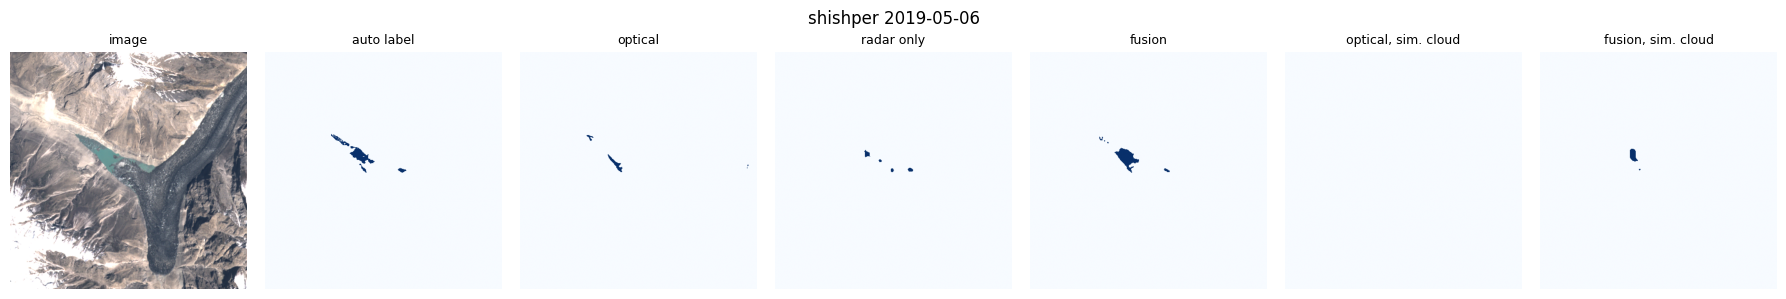

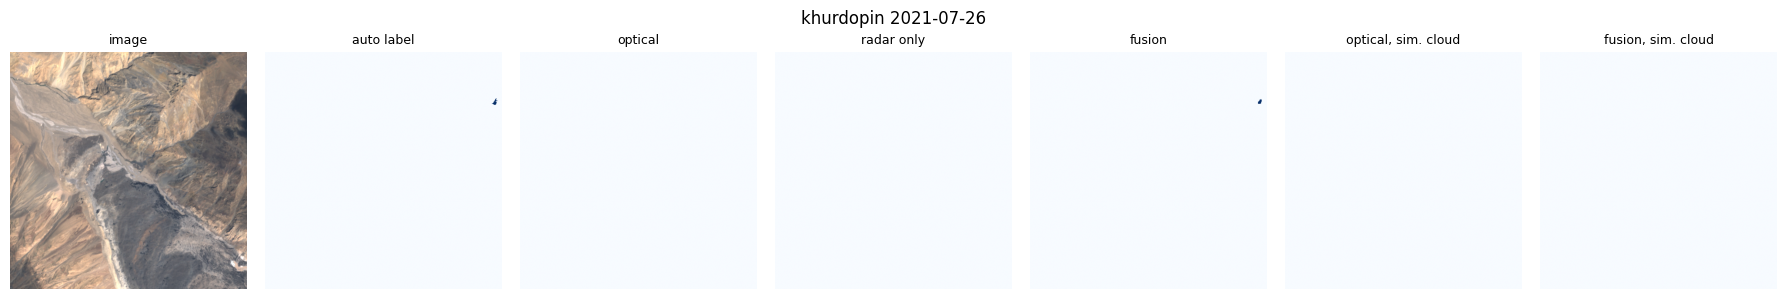

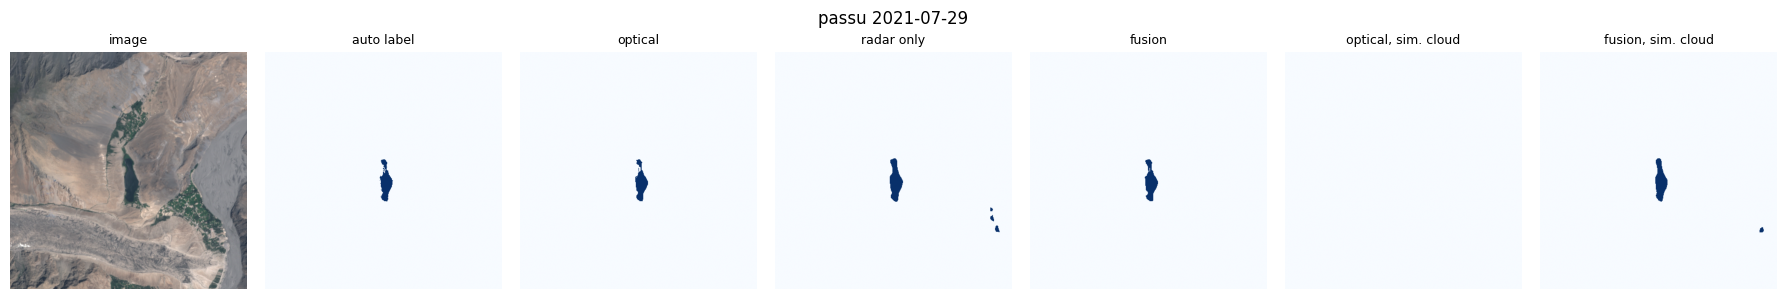

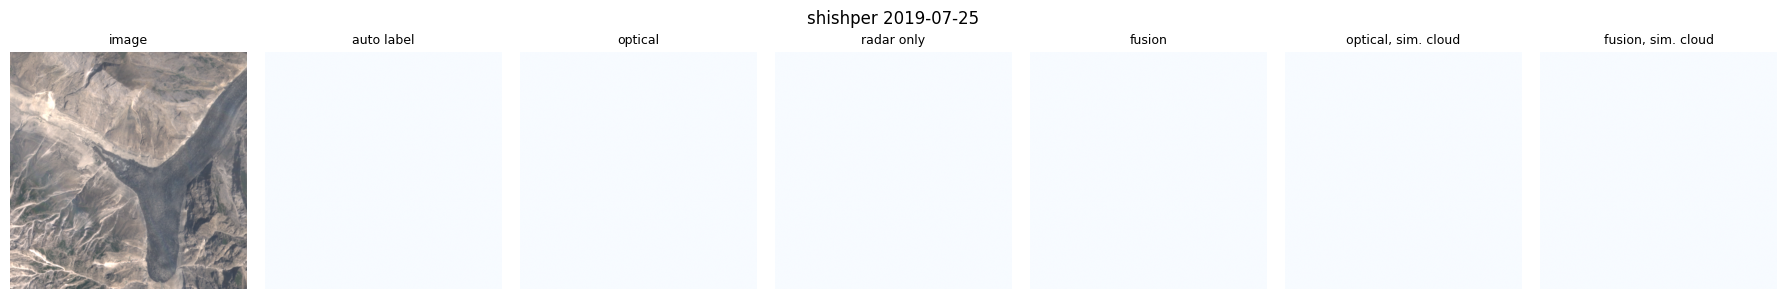

In [18]:
# Qualitative examples (3-seed ensembles): three test images with water and one without.
has_water = [(n, t) for n, t in test_idx if (DATA[n]["label"][t] == 1).any()]
no_water = [(n, t) for n, t in test_idx if not (DATA[n]["label"][t] == 1).any()]
picks = [has_water[i] for i in np.linspace(0, len(has_water) - 1, min(3, len(has_water))).astype(int)] + no_water[:1]
for n, t in picks:
    x = DATA[n]["xn"][t]; x_cloud = x.copy(); x_cloud[:N_OPT] = 0
    panels = [("image", rgb(DATA[n]["s2"][t])), ("auto label", DATA[n]["label"][t] == 1),
              ("optical", predict_ens("optical", x[OPTICAL])), ("radar only", predict_ens("radar", x[RADAR])),
              ("fusion", predict_ens("fusion", x[FUSION])),
              ("optical, sim. cloud", predict_ens("optical", x_cloud[OPTICAL])),
              ("fusion, sim. cloud", predict_ens("fusion", x_cloud[FUSION]))]
    fig, axes = plt.subplots(1, 7, figsize=(18, 3))
    for a, (title, img) in zip(axes, panels):
        a.imshow(img, cmap=None if img.ndim == 3 else "Blues"); a.set_title(title, fontsize=9); a.axis("off")
    day = DATA[n]["meta"].date[t].date()
    fig.suptitle(f"{n} {day}"); plt.tight_layout(); savefig(f"prediction_{n}_{day}.png"); plt.show()

In [19]:
# Computational cost: model size, training time, peak GPU memory and inference time per 448 x 448 image.
def inference_ms(model, channels, n=20):
    xs = [DATA[l]["xn"][t][channels] for l, t in test_idx[:n]]
    predict(model, xs[0])                                   # warm-up
    t0 = time.time()
    for x in xs:
        predict(model, x)                                   # .cpu() inside predict synchronises the GPU
    return round((time.time() - t0) / len(xs) * 1000, 1)


compute_df = pd.DataFrame(compute)
compute_df.to_csv(os.path.join(CACHE_DIR, "compute_by_seed.csv"), index=False)
compute_summary = (compute_df.groupby("model", sort=False)
                   .agg(channels=("channels", "first"), parameters=("parameters", "first"),
                        train_minutes_mean=("train_minutes", "mean"), train_minutes_std=("train_minutes", "std"),
                        peak_gpu_memory_gb=("peak_gpu_memory_gb", "max")).round(2).reset_index())
compute_summary["inference_ms_per_image"] = [inference_ms(models[(m, 0)], MODELS[m][0]) for m in compute_summary.model]
compute_summary.to_csv(os.path.join(CACHE_DIR, "compute.csv"), index=False)
compute_summary

,model,channels,parameters,train_minutes_mean,train_minutes_std,peak_gpu_memory_gb,inference_ms_per_image
0,optical,5,14334481,3.11,0.02,0.83,26.3
1,radar,4,14331345,3.10,0.00,1.18,26.0
2,fusion,9,14347025,3.25,0.00,1.53,28.8


## 9. Lake-area time series

The fusion model (mean probability of its three seeds) is run on **every** date — clear optical, cloudy optical and radar-only. Lake area = predicted water connected to the lake point (within `LAKE_RADIUS_M`), so rivers and other ponds in the box are not counted.

Single dates are noisy, so area is smoothed with a rolling median of 3 observations, and growth rate is the change in smoothed area over the previous ~30 days (no growth is computed across gaps longer than 60 days, e.g. between windows).

In [20]:
def lake_mask(pred, rc):
    comp = cc_label(pred)
    r, c = rc; k = LAKE_RADIUS_M // PIX
    ids = np.unique(comp[max(r - k, 0):r + k + 1, max(c - k, 0):c + k + 1])
    return np.isin(comp, ids[ids > 0])


def growth_30d(g):
    # change in smoothed area since the latest date >= 30 days earlier, per 30 days
    left = pd.DataFrame({"ref": g.date - pd.Timedelta(days=30)})
    right = g[["date", "area_smooth"]].rename(columns={"date": "ref_date", "area_smooth": "ref_area"})
    prev = pd.merge_asof(left, right, left_on="ref", right_on="ref_date", direction="backward")
    days = (g.date.values - prev.ref_date.values) / np.timedelta64(1, "D")
    growth = (g.area_smooth.values - prev.ref_area.values) / days * 30
    return np.where(days <= 60, growth, np.nan)


series = []
for name, d in DATA.items():
    for t, m in d["meta"].iterrows():
        mask = lake_mask(predict_ens("fusion", d["xn"][t][FUSION]), LAKES[name]["lake_rc"])
        edge = np.abs(np.gradient(mask.astype(float))).sum(0) > 0          # lake outline
        source = "radar only" if not m.s2 else ("optical clear" if m.cloud_frac < 0.3 else "optical cloudy")
        series.append(dict(lake=name, date=m.date, source=source, area_km2=mask.sum() * PIX * PIX / 1e6,
                           slope_deg=float(np.nanmean(d["slope"][edge])) if edge.any() else np.nan))
ts = pd.DataFrame(series).sort_values(["lake", "date"]).reset_index(drop=True)
ts["area_smooth"] = ts.groupby("lake").area_km2.transform(lambda s: s.rolling(3, center=True, min_periods=1).median())
ts["growth_km2_per_30d"] = np.concatenate([growth_30d(g.reset_index(drop=True)) for _, g in ts.groupby("lake", sort=True)])
ts.groupby(["lake", "source"]).size().unstack()

source,optical clear,optical cloudy,radar only
lake,,,
khurdopin,127,121,65
passu,67,54,81
shishper,56,65,94


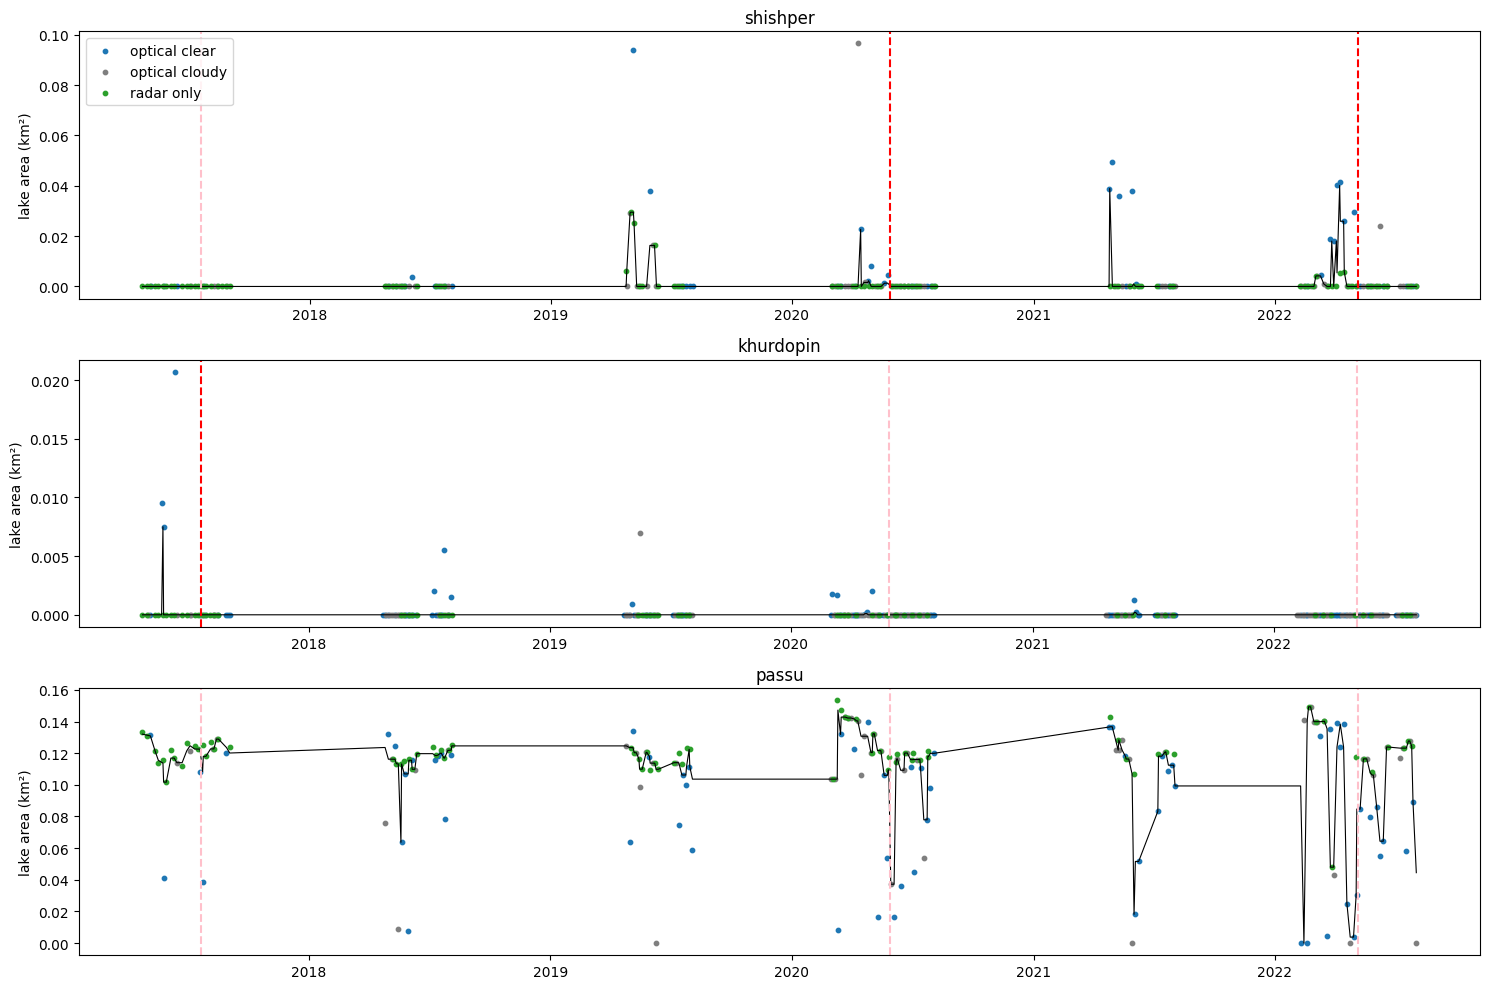

In [21]:
COLORS = {"optical clear": "tab:blue", "optical cloudy": "tab:gray", "radar only": "tab:green"}
fig, axes = plt.subplots(3, 1, figsize=(15, 10))
for a, name in zip(axes, LAKES):
    g = ts[ts.lake == name]
    for src, gg in g.groupby("source"):
        a.scatter(gg.date, gg.area_km2, s=10, color=COLORS[src], label=src)
    a.plot(g.date, g.area_smooth, color="k", lw=0.8)
    for label, day in ALL_EVENTS.items():
        a.axvline(day, color="r" if label in LAKES[name]["events"] else "pink", ls="--")
    a.set_title(name); a.set_ylabel("lake area (km²)")
axes[0].legend(loc="upper left")
plt.tight_layout(); savefig("lake_area_timeseries.png"); plt.show()

## 10. Hazard score

A transparent, equal-weight index (not a trained model):

`score = (area_norm + growth_norm + slope_norm) / 3`

Each feature is min–max scaled to 0–1 over all lakes and dates; only growth (positive change) adds to the score. Glacier distance is left out to keep this minimal. This is a look back at past events, not an early-warning system.

The second figure compares **all three lakes over each event window**: the event lake should score higher before its event than the other two lakes over the same days.

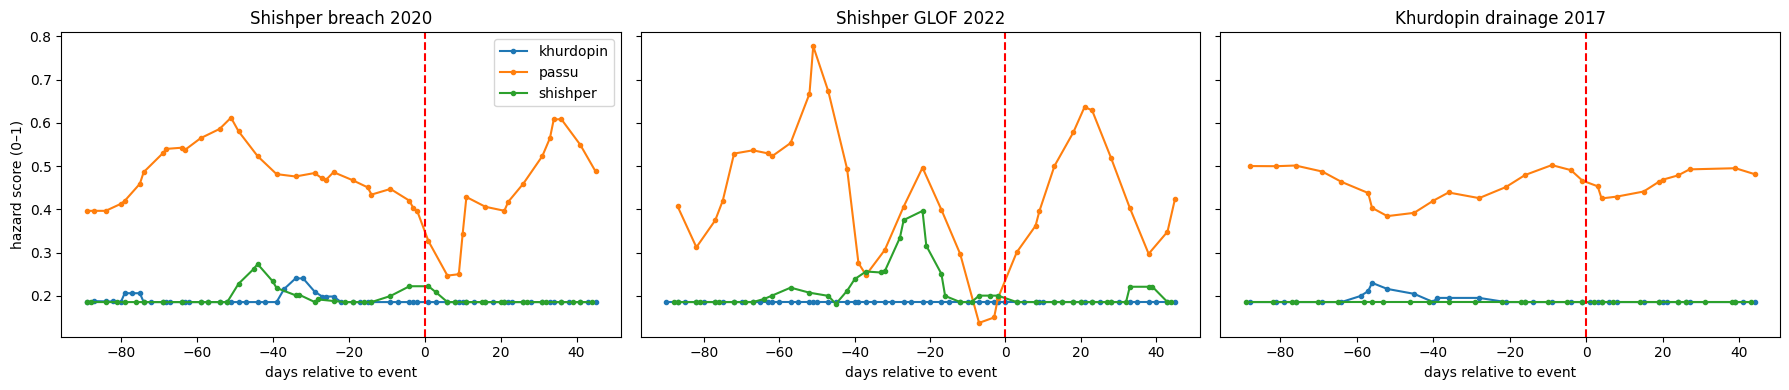

,event,lake,mean_score_before,max_score_before,n_dates_before
0,Shishper breach 2020,khurdopin,0.192,0.276,43
1,Shishper breach 2020,passu,0.479,0.626,29
2,Shishper breach 2020,shishper,0.200,0.313,29
3,Shishper GLOF 2022,khurdopin,0.185,0.185,40
4,Shishper GLOF 2022,passu,0.419,0.864,23
5,Shishper GLOF 2022,shishper,0.223,0.470,31
6,Khurdopin drainage 2017,khurdopin,0.193,0.243,21
7,Khurdopin drainage 2017,passu,0.453,0.516,17
8,Khurdopin drainage 2017,shishper,0.185,0.185,19


In [22]:
def minmax(s):
    s = s.astype(float)
    return (s - s.min()) / (s.max() - s.min() + 1e-9)

ts["area_n"] = minmax(ts.area_smooth)
ts["growth_n"] = minmax(ts.growth_km2_per_30d.clip(lower=0).fillna(0))
ts["slope_n"] = minmax(ts.slope_deg.fillna(ts.slope_deg.mean()))
ts["hazard"] = (ts.area_n + ts.growth_n + ts.slope_n) / 3
ts.to_csv(os.path.join(CACHE_DIR, "lake_timeseries.csv"), index=False)

def event_windows(col, ylabel, name):
    # Plot `col` for all lakes around each event; return mean / max over the 90 days before each event.
    fig, axes = plt.subplots(1, len(ALL_EVENTS), figsize=(6 * len(ALL_EVENTS), 4), sharey=True, squeeze=False)
    summary = []
    for a, (label, day) in zip(axes[0], ALL_EVENTS.items()):
        w = ts[(ts.date >= day - pd.Timedelta(days=DAYS_BEFORE)) & (ts.date <= day + pd.Timedelta(days=DAYS_AFTER))]
        for lake, g in w.groupby("lake"):
            a.plot((g.date - day).dt.days, g[col].rolling(3, min_periods=1).mean(), "o-", ms=3, label=lake)
            before = g[g.date < day]
            summary.append(dict(event=label, lake=lake, mean_score_before=before[col].mean(),
                                max_score_before=before[col].max(), n_dates_before=len(before)))
        a.axvline(0, color="r", ls="--"); a.set_title(label); a.set_xlabel("days relative to event")
    axes[0, 0].set_ylabel(ylabel); axes[0, 0].legend()
    plt.tight_layout(); savefig(name + ".png"); plt.show()
    out = pd.DataFrame(summary).round(3)
    out.to_csv(os.path.join(CACHE_DIR, name.replace("event_windows", "summary") + ".csv"), index=False)
    return out


event_windows("hazard", "hazard score (0–1)", "hazard_event_windows")

## 11. Exploratory: per-lake normalised hazard index

*This analysis was added after inspecting the results of section 10 and is a follow-up, not the main result.*

In section 10 every feature is min–max scaled across all three lakes, so the largest lake (Borith) dominates the area term whether or not it is changing. Here each lake is compared with **its own normal state**: smoothed area and positive growth are converted to z-scores within each lake, and the index is their mean:

`score_site = (z_area + z_growth) / 2`, with `z = (x − mean of that lake) / std of that lake`

Slope is left out because it barely varies within a lake. A high value means "unusually large and growing for this lake".

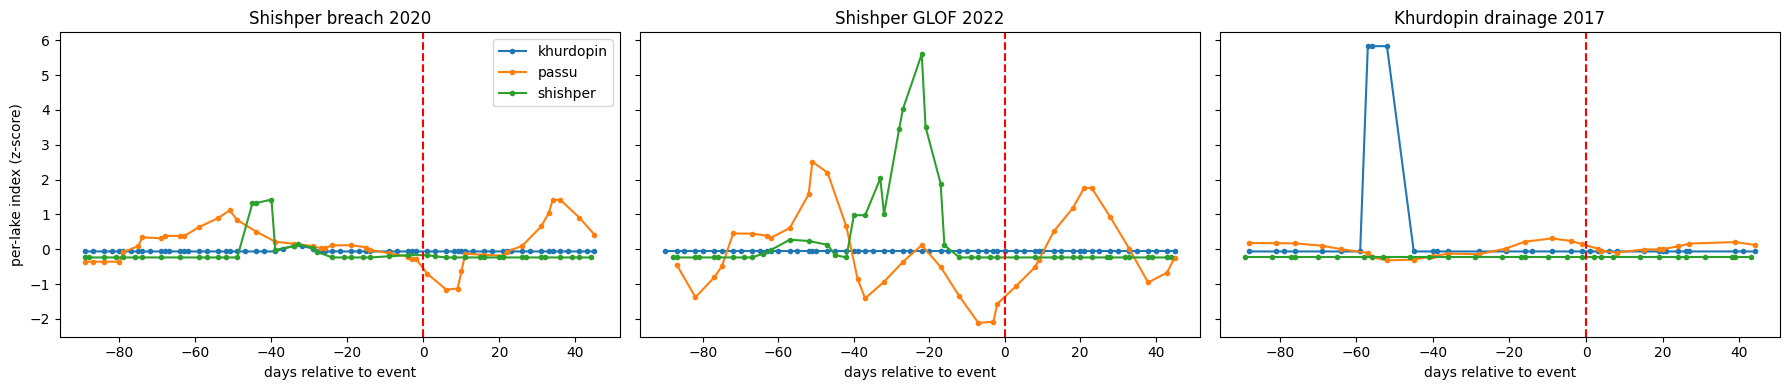

,event,lake,mean_score_before,max_score_before,n_dates_before
0,Shishper breach 2020,khurdopin,-0.050,0.179,43
1,Shishper breach 2020,passu,0.153,1.172,29
2,Shishper breach 2020,shishper,-0.015,4.446,29
3,Shishper GLOF 2022,khurdopin,-0.061,-0.061,40
4,Shishper GLOF 2022,passu,-0.229,3.231,23
5,Shishper GLOF 2022,shishper,0.660,7.079,31
6,Khurdopin drainage 2017,khurdopin,0.781,17.619,21
7,Khurdopin drainage 2017,passu,0.009,0.439,17
8,Khurdopin drainage 2017,shishper,-0.233,-0.233,19


In [23]:
def zscore(s):
    s = s.astype(float)
    sd = s.std()
    return (s - s.mean()) / sd if sd > 0 else s * 0


ts["growth_pos"] = ts.growth_km2_per_30d.clip(lower=0).fillna(0)
ts["z_area"] = ts.groupby("lake").area_smooth.transform(zscore)
ts["z_growth"] = ts.groupby("lake").growth_pos.transform(zscore)
ts["hazard_site"] = (ts.z_area + ts.z_growth) / 2
ts.to_csv(os.path.join(CACHE_DIR, "lake_timeseries.csv"), index=False)

event_windows("hazard_site", "per-lake index (z-score)", "hazard_site_event_windows")

## 12. Summary

- **Segmentation:** section 8 compares the optical-only, radar-only and fusion models (3 seeds each, mean ± sd) on held-out years (pixel-pooled, per image with water, false positives without water), normally and under simulated cloud, plus their computational cost.
- **Time series:** section 9 shows each lake's area across all windows, using optical and radar-only dates.
- **Hazard:** section 10 checks whether the event lake scores higher than the other lakes in the 90 days before each event; section 11 repeats this with a per-lake normalised index (exploratory).

**Limitations:** labels are automatic (from optical NDWI) rather than hand-drawn; frozen/snow-covered lakes are labelled as land; the 30 m DEM is resampled to 10 m; equal hazard weights are an assumption; Sentinel-1B failed in Dec 2021, so 2022 radar is sparser.

Results are saved to `CACHE_DIR`: segmentation tables (`seg_*.csv`, `segmentation_results.csv`), `compute.csv`, `compute_by_seed.csv`, `lake_timeseries.csv`, `hazard_summary.csv`, `hazard_site_summary.csv`, `models.pt`, and all figures in `figures/`.